In [6]:
from datasets import load_dataset
import pandas as pd
from nltk.tokenize import sent_tokenize
from collections import Counter
import torch

ds = load_dataset("papluca/language-identification")

In [7]:
print (ds)

DatasetDict({
    train: Dataset({
        features: ['labels', 'text'],
        num_rows: 70000
    })
    validation: Dataset({
        features: ['labels', 'text'],
        num_rows: 10000
    })
    test: Dataset({
        features: ['labels', 'text'],
        num_rows: 10000
    })
})


In [8]:
print (ds["train"].features)

{'labels': Value('string'), 'text': Value('string')}


In [9]:
ds["train"].unique("labels")

['pt',
 'bg',
 'zh',
 'th',
 'ru',
 'pl',
 'ur',
 'sw',
 'tr',
 'es',
 'ar',
 'it',
 'hi',
 'de',
 'el',
 'nl',
 'fr',
 'vi',
 'en',
 'ja']

In [10]:
pd.Series(ds["train"]["labels"]).value_counts()

,count
pt,3500
bg,3500
zh,3500
th,3500
ru,3500
pl,3500
ur,3500
sw,3500
tr,3500
es,3500


# **TOKENIZATION**

In [11]:
def tokenize(text):
    return text.split()

In [12]:
train_tokens = [tokenize(text) for text in ds["train"]["text"]]

In [13]:
print (train_tokens[0])

['os', 'chefes', 'de', 'defesa', 'da', 'estónia,', 'letónia,', 'lituânia,', 'alemanha,', 'itália,', 'espanha', 'e', 'eslováquia', 'assinarão', 'o', 'acordo', 'para', 'fornecer', 'pessoal', 'e', 'financiamento', 'para', 'o', 'centro.']


In [14]:
token_counts = Counter()

for tokens in train_tokens:
    token_counts.update(tokens)

In [15]:
print (token_counts)

Counter({',': 33343, '.': 23405, '्': 12514, 'de': 10999, 'a': 7482, 'la': 5764, 'the': 5525, 'que': 4875, 'na': 4594, 'на': 4507, 'ya': 4439, 'in': 4361, "'": 4196, 'и': 3990, 'I': 3981, ')': 3973, '(': 3912, 'в': 3602, 'के': 3566, 'کے': 3419, 'to': 3344, 'and': 3331, 'y': 3314, 'un': 3268, 'ہے': 3257, 'है': 3256, 'en': 3144, 'میں': 3092, 'ที่': 3089, 'es': 2922, 'und': 2825, 'die': 2772, 'le': 2749, 'ของ': 2690, 'no': 2649, 'it': 2642, 'کی': 2571, 'el': 2386, 'của': 2293, '۔': 2256, 'में': 2161, 'και': 2141, 'да': 2136, 'wa': 2108, 'ist': 2093, '،': 2088, 'một': 2070, 'और': 2056, 'is': 2046, 'และ': 2012, 'من': 2005, 'et': 2000, 'nicht': 1996, 'να': 1953, 'và': 1916, '?': 1892, 've': 1878, 'pas': 1871, 'في': 1869, 'para': 1845, 'of': 1789, 'bir': 1773, 'à': 1747, 'se': 1725, 'за': 1709, 'سے': 1708, 'der': 1702, 'το': 1697, 'kwa': 1665, 'ان': 1656, 'di': 1629, 'for': 1618, 'не': 1600, 'là': 1599, 'اس': 1598, 'da': 1592, 'con': 1592, 'е': 1588, 'ใน': 1578, 'w': 1550, 'کہ': 1549, 'एक': 1

In [16]:
MAX_VOCAB_SIZE = 50000

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

vocab = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

for token, count in token_counts.most_common(MAX_VOCAB_SIZE - 2):
    vocab[token] = len(vocab)

print("Vocabulary size:", len(vocab))
print("PAD index:", vocab[PAD_TOKEN])
print("UNK index:", vocab[UNK_TOKEN])

Vocabulary size: 50000
PAD index: 0
UNK index: 1


In [17]:
def text_to_ids(text):
    tokens = tokenize(text)
    return [vocab.get(token, vocab[UNK_TOKEN]) for token in tokens]

print(text_to_ids(ds["train"]["text"][0])[:20])

[549, 1, 5, 9493, 77, 1, 1, 1, 1, 1, 1, 134, 1, 1, 99, 3063, 61, 39120, 24954, 134]


In [18]:
MAX_LEN = 64

def encode_and_pad(text):
    ids = text_to_ids(text)

    if len(ids) > MAX_LEN:
        ids = ids[:MAX_LEN]
    else:
        ids = ids + [vocab[PAD_TOKEN]] * (MAX_LEN - len(ids))

    return ids

print(encode_and_pad(ds["train"]["text"][0]))
print("Sequence length:", len(encode_and_pad(ds["train"]["text"][0])))

[549, 1, 5, 9493, 77, 1, 1, 1, 1, 1, 1, 134, 1, 1, 99, 3063, 61, 39120, 24954, 134, 24955, 61, 99, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Sequence length: 64


In [19]:
label_names = sorted(ds["train"].unique("labels"))

label_to_id = {
    label: i
    for i, label in enumerate(label_names)
}

id_to_label = {
    i: label
    for label, i in label_to_id.items()
}

print("Number of classes:", len(label_names))
print("Label mapping:", label_to_id)

Number of classes: 20
Label mapping: {'ar': 0, 'bg': 1, 'de': 2, 'el': 3, 'en': 4, 'es': 5, 'fr': 6, 'hi': 7, 'it': 8, 'ja': 9, 'nl': 10, 'pl': 11, 'pt': 12, 'ru': 13, 'sw': 14, 'th': 15, 'tr': 16, 'ur': 17, 'vi': 18, 'zh': 19}


In [20]:
def prepare_split(split):
    texts = ds[split]["text"]
    labels = ds[split]["labels"]

    X = torch.tensor(
        [encode_and_pad(text) for text in texts],
        dtype=torch.long
    )

    y = torch.tensor(
        [label_to_id[label] for label in labels],
        dtype=torch.long
    )

    return X, y


X_train, y_train = prepare_split("train")
X_val, y_val = prepare_split("validation")
X_test, y_test = prepare_split("test")

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: torch.Size([70000, 64]) torch.Size([70000])
Validation: torch.Size([10000, 64]) torch.Size([10000])
Test: torch.Size([10000, 64]) torch.Size([10000])


In [21]:
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 128

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))
print("Number of test batches:", len(test_loader))

Number of training batches: 547
Number of validation batches: 79
Number of test batches: 79


In [22]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [23]:
import torch.nn as nn

EMBED_DIM = 128
HIDDEN_DIM = 128
NUM_LAYERS = 1
DROPOUT = 0.30
NUM_CLASSES = len(label_names)

class LanguageLSTM(nn.Module):

    def __init__(
        self,
        vocab_size,
        embed_dim,
        hidden_dim,
        num_layers,
        num_classes,
        dropout
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embed_dim,
            padding_idx=vocab[PAD_TOKEN]
        )

        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Linear(
            hidden_dim * 2,
            num_classes
        )

    def forward(self, x):
        embedded = self.embedding(x)

        output, (hidden, cell) = self.lstm(embedded)

        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        combined_hidden = torch.cat(
            (forward_hidden, backward_hidden),
            dim=1
        )

        combined_hidden = self.dropout(
            combined_hidden
        )

        logits = self.classifier(
            combined_hidden
        )

        return logits

In [24]:
model = LanguageLSTM(
    vocab_size=len(vocab),
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    num_classes=NUM_CLASSES,
    dropout=DROPOUT
).to(device)

print(model)

LanguageLSTM(
  (embedding): Embedding(50000, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=256, out_features=20, bias=True)
)


In [25]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [26]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * inputs.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    epoch_loss = total_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [27]:
def evaluate(
    model,
    loader,
    criterion,
    device
):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * inputs.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    epoch_loss = total_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [28]:
import copy

NUM_EPOCHS = 8
PATIENCE = 2

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0

for epoch in range(NUM_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break

if best_state is not None:
    model.load_state_dict(best_state)

Epoch 1/8 | Train Loss: 0.8920 | Train Acc: 0.7504 | Val Loss: 0.8069 | Val Acc: 0.7886
Epoch 2/8 | Train Loss: 0.2305 | Train Acc: 0.9247 | Val Loss: 0.6752 | Val Acc: 0.8359
Epoch 3/8 | Train Loss: 0.1575 | Train Acc: 0.9457 | Val Loss: 0.7591 | Val Acc: 0.8252
Epoch 4/8 | Train Loss: 0.1257 | Train Acc: 0.9543 | Val Loss: 0.8824 | Val Acc: 0.8139
Early stopping.


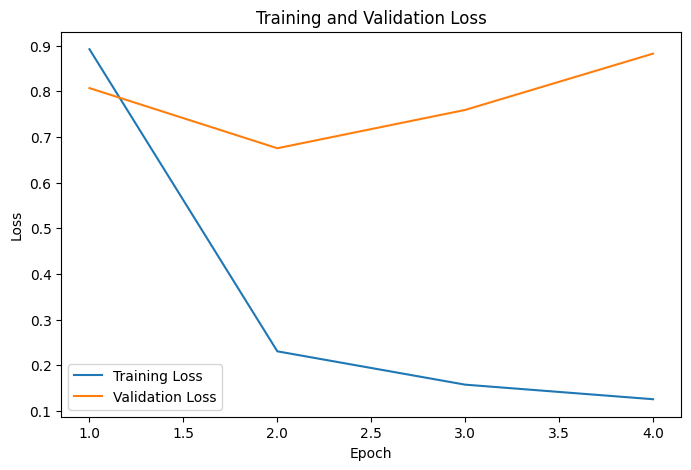

In [29]:
import matplotlib.pyplot as plt

epochs = range(
    1,
    len(history["train_loss"]) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

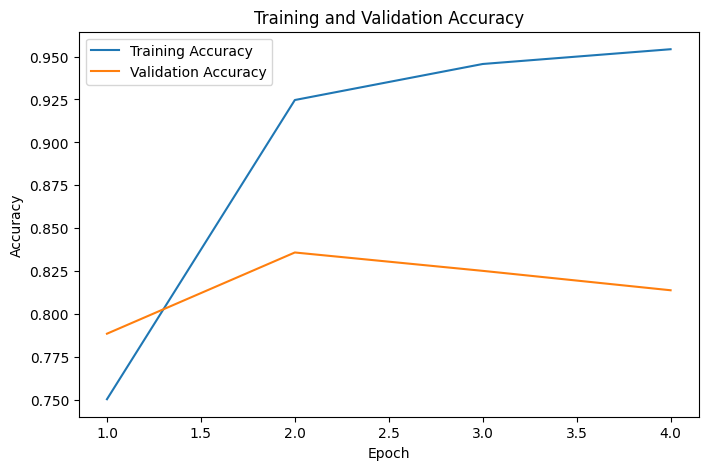

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

In [31]:
test_loss, test_accuracy = evaluate(
    model,
    test_loader,
    criterion,
    device
)

print(f"Final Test Loss: {test_loss:.4f}")
print(f"Final Test Accuracy: {test_accuracy:.4f}")
print(f"Final Test Accuracy (%): {test_accuracy * 100:.2f}%")

Final Test Loss: 0.6884
Final Test Accuracy: 0.8332
Final Test Accuracy (%): 83.32%


In [32]:
from sklearn.metrics import classification_report

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(device)

        outputs = model(inputs)

        predictions = outputs.argmax(
            dim=1
        ).cpu()

        all_predictions.extend(
            predictions.tolist()
        )

        all_labels.extend(
            labels.tolist()
        )

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=label_names,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

          ar     0.9691    0.8160    0.8860       500
          bg     0.9844    0.8820    0.9304       500
          de     0.9677    0.9600    0.9639       500
          el     0.9677    0.9600    0.9639       500
          en     0.9604    0.9700    0.9652       500
          es     0.9607    0.9780    0.9693       500
          fr     0.9436    0.9700    0.9566       500
          hi     1.0000    0.7420    0.8519       500
          it     0.9042    0.9440    0.9237       500
          ja     0.3515    0.5560    0.4307       500
          nl     0.8445    0.9560    0.8968       500
          pl     0.5693    0.9360    0.7080       500
          pt     0.9175    0.9340    0.9257       500
          ru     0.9229    0.8380    0.8784       500
          sw     0.9583    0.7820    0.8612       500
          th     0.3474    0.0660    0.1109       500
          tr     0.9356    0.7260    0.8176       500
          ur     0.9472    

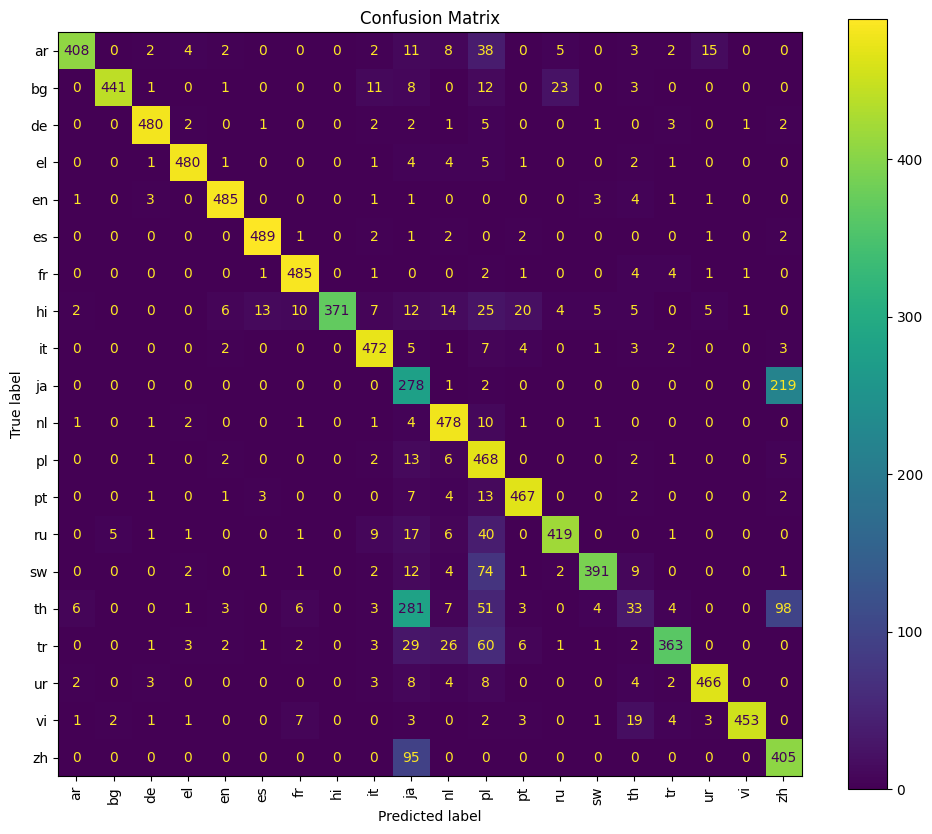

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    all_labels,
    all_predictions
)

fig, ax = plt.subplots(
    figsize=(12, 10)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_names
)

disp.plot(
    ax=ax,
    xticks_rotation=90
)

plt.title("Confusion Matrix")
plt.show()

In [34]:
def predict_language(
    text,
    model,
    vocab,
    id_to_label
):

    model.eval()

    encoded = encode_and_pad(text)

    input_tensor = torch.tensor(
        [encoded],
        dtype=torch.long
    ).to(device)

    with torch.no_grad():

        logits = model(input_tensor)

        probabilities = torch.softmax(
            logits,
            dim=1
        )

    predicted_id = probabilities.argmax(
        dim=1
    ).item()

    predicted_language = id_to_label[
        predicted_id
    ]

    class_probabilities = {
        id_to_label[i]:
        float(probabilities[0, i].item())
        for i in range(len(id_to_label))
    }

    return (
        predicted_language,
        class_probabilities
    )

In [35]:
sample_texts = [
    "This is a simple English sentence.",
    "Ceci est une phrase française simple.",
    "Dies ist ein deutscher Satz."
]

for text in sample_texts:

    predicted_language, probabilities = predict_language(
        text,
        model,
        vocab,
        id_to_label
    )

    print("Text:", text)
    print("Predicted language:", predicted_language)
    print(
        "Confidence:",
        f"{probabilities[predicted_language] * 100:.2f}%"
    )
    print()

Text: This is a simple English sentence.
Predicted language: en
Confidence: 88.11%

Text: Ceci est une phrase française simple.
Predicted language: fr
Confidence: 57.87%

Text: Dies ist ein deutscher Satz.
Predicted language: de
Confidence: 96.06%



In [37]:
text = "This is an example "

predicted_language, probabilities = predict_language(
    text,
    model,
    vocab,
    id_to_label
)

sorted_probabilities = sorted(
    probabilities.items(),
    key=lambda item: item[1],
    reverse=True
)

print("Input:", text)
print("Predicted language:", predicted_language)
print("\nClass probabilities:")

for language, probability in sorted_probabilities:
    print(
        f"{language}: "
        f"{probability * 100:.2f}%"
    )

Input: This is an example 
Predicted language: en

Class probabilities:
en: 69.90%
nl: 17.74%
de: 5.03%
tr: 1.56%
fr: 1.43%
pt: 1.25%
it: 0.80%
el: 0.50%
pl: 0.39%
es: 0.30%
sw: 0.29%
ur: 0.22%
ja: 0.15%
ar: 0.12%
zh: 0.10%
th: 0.08%
hi: 0.05%
ru: 0.03%
bg: 0.03%
vi: 0.02%


In [38]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "vocab": vocab,
        "label_to_id": label_to_id,
        "id_to_label": id_to_label,
        "max_len": MAX_LEN,
        "embed_dim": EMBED_DIM,
        "hidden_dim": HIDDEN_DIM,
        "num_layers": NUM_LAYERS,
        "dropout": DROPOUT
    },
    "multilingual_language_identifier.pt"
)

print("Model saved successfully.")

Model saved successfully.
